# Empirical Recreation of Dauphin et al.: MSGD and damped Newton

**Date: 2026/11/16**

*Author: KATO Kengo*

A single hidden-layer classifier on 10 × 10 MNIST and CIFAR-10 images. Compare MSGD and damped Newton on MNIST at 5, 25 and 50 hidden units. The reusable implementation is in `src/`; this notebook only selects and runs experiments.

Dauphin et al., [Figure 3 and Appendix F.1](https://arxiv.org/pdf/1406.2572v1): training classification error versus hidden units and epochs, plus the magnitude of the most negative Hessian eigenvalue. Cross entropy is our training loss; error means the percentage of wrongly classified training images.

In [1]:
from src.training.main import run_experiments
from src.pipelines.cifar import run_cifar_pipeline
from src.pipelines.mnist import run_mnist_pipeline
from src.training.config import ExperimentConfig, mnist_preprint_configs
from src.pipelines.load.loader import DATA_DIR
from src.utils.visuals.mlp_plots.training_error_by_epoch import plot_training_error_by_epoch
from src.utils.visuals.mlp_plots.negative_curvature_by_epoch import plot_negative_curvature_by_epoch
from src.utils.visuals.mlp_plots.training_error_by_hidden_units import \
    plot_training_error_by_hidden_units

import json
import torch
import matplotlib.pyplot as plt

ROOT = DATA_DIR.parent


## Configure the experiments

Each `ExperimentConfig` describes **one run**: dataset, method, hidden units, learning rate, momentum, batch size, epochs and seed. The learning rate stays constant during that run. Add configurations to compare other settings.

Start with the three MNIST SGD settings from [Table 1 of the earlier preprint](https://arxiv.org/pdf/1405.4604v2): widths 5 / 25 / 50, learning rates 0.074 / 0.040 / 0.015, momenta 0.031 / 0.017 / 0.254, batch sizes 10 / 10 / 1. These are historical MNIST settings, not verified CIFAR-10 settings. The notebook keeps your 100-epoch choice and uses only 512 training examples initially; this is a small trial, not a reproduction of the full-data results. Set `train_limit=None` for the complete prepared training split.

The existing transforms, tanh model, PyTorch default initialization and CPU float64 stay in use. Curvature diagnostics remain disabled to avoid an extra Hessian calculation after each epoch. Newton still computes a full Hessian for every update. Its configurations explicitly raise the parameter limit to 6,000 so all three MNIST widths fit (565, 2,785 and 5,560 parameters). The 50-unit Hessian alone occupies about 236 MiB in float64, with additional working memory during differentiation.

Newton uses `learning_rate=1.0`, no momentum and `batch_size=None`: one update on the complete selected training subset per epoch. Both methods use the same 512 images, seed and epoch budget. The six configured runs are MNIST only. These dense Newton runs can take substantially longer than MSGD.

In [2]:
EPOCHS = 100
TRAIN_LIMIT = 512
SEED = 42
NEWTON_MAX_PARAMETERS = 6000  # Allows the 5,560-parameter MNIST model.

configs = mnist_preprint_configs(epochs=EPOCHS, train_limit=TRAIN_LIMIT, seed=SEED)
configs += [
    ExperimentConfig(
        dataset="mnist", method="damped_newton", hidden_units=width,
        learning_rate=1.0, momentum=0.0, batch_size=None,
        epochs=EPOCHS, train_limit=TRAIN_LIMIT, seed=SEED,
        curvature_samples=0, max_parameters=NEWTON_MAX_PARAMETERS,
    )
    for width in (5, 25, 50)
]
for config in configs:
    print(config)

ExperimentConfig(dataset='mnist', method='msgd', hidden_units=5, learning_rate=0.074, momentum=0.031, batch_size=10, epochs=100, train_limit=512, curvature_samples=0, max_parameters=2000, seed=42, name=None)
ExperimentConfig(dataset='mnist', method='msgd', hidden_units=25, learning_rate=0.04, momentum=0.017, batch_size=10, epochs=100, train_limit=512, curvature_samples=0, max_parameters=2000, seed=42, name=None)
ExperimentConfig(dataset='mnist', method='msgd', hidden_units=50, learning_rate=0.015, momentum=0.254, batch_size=1, epochs=100, train_limit=512, curvature_samples=0, max_parameters=2000, seed=42, name=None)
ExperimentConfig(dataset='mnist', method='damped_newton', hidden_units=5, learning_rate=1.0, momentum=0.0, batch_size=None, epochs=100, train_limit=512, curvature_samples=0, max_parameters=6000, seed=42, name=None)
ExperimentConfig(dataset='mnist', method='damped_newton', hidden_units=25, learning_rate=1.0, momentum=0.0, batch_size=None, epochs=100, train_limit=512, curvatu

## Prepare any missing data

Only datasets named in the configurations are prepared. Existing exports are reused, hence the pipeline is idempotent. If an export is missing, the existing preparation pipeline runs once. Adding CIFAR-10 may therefore trigger its download and preparation.

The runner reads the prepared training tensors and reuses them for configurations with the same dataset and sample limit. Validation and test examples stay out of training and curvature measurements!

In [3]:
pipelines = {"mnist": run_mnist_pipeline, "cifar10": run_cifar_pipeline}
for name in dict.fromkeys(config.dataset for config in configs):
    if not (DATA_DIR / "processed" / name / "train.pt").exists():
        pipelines[name]()

## Train

Pass the configuration list to the runner. Each run starts from its configured seed with a fresh model, optimizer and shuffled DataLoader. Matching seeds repeat the initialization for the same width. Batch size can differ between runs. History includes epoch zero and the end of every epoch.

Each result contains `config`, `training_examples`, `parameter_count` and `history`. For example, `results[0]["history"][-1]` gives the first run's final measurements.

The optional damped Newton reference tries positive-definite shifts from the damping grid `1, 0.1, 0.01, 0.001, 0.0001, 0.00001`. It accepts the candidate with the lowest improving loss on its update batch. This remains our explicit reference policy; these presets do not claim to recover every detail of the original experiment.

The entry point is `src.training.main.run_experiments`. The runner builds the model, then selects `msgd_training` or `damped_training`. Both reuse the epoch loop in `training/common.py`.

In [4]:
results = run_experiments(configs)

Run 1: mnist | msgd | h=5 | lr=0.074 | momentum=0.031 | batch=10
Epoch 1: loss=2.2375, train error=77.54%
Epoch 2: loss=2.1294, train error=62.30%
Epoch 3: loss=1.9898, train error=51.95%
Epoch 4: loss=1.8279, train error=46.48%
Epoch 5: loss=1.6716, train error=44.73%
Epoch 6: loss=1.5200, train error=41.80%
Epoch 7: loss=1.4041, train error=41.41%
Epoch 8: loss=1.2837, train error=34.38%
Epoch 9: loss=1.2153, train error=32.23%
Epoch 10: loss=1.1224, train error=30.08%
Epoch 11: loss=1.0816, train error=31.84%
Epoch 12: loss=1.0040, train error=30.27%
Epoch 13: loss=0.9599, train error=28.52%
Epoch 14: loss=0.9209, train error=24.41%
Epoch 15: loss=0.8904, train error=25.59%
Epoch 16: loss=0.8768, train error=24.41%
Epoch 17: loss=0.8263, train error=24.22%
Epoch 18: loss=0.7981, train error=23.24%
Epoch 19: loss=0.7709, train error=21.48%
Epoch 20: loss=0.7624, train error=20.31%
Epoch 21: loss=0.7325, train error=19.14%
Epoch 22: loss=0.7225, train error=19.34%
Epoch 23: loss=0.686

## Plot and save

Every run appears in the epoch curves. The width panel shows the lowest observed training error for each method and width, including repeated trials. These are single-seed observations. Curvature appears only when requested; it uses a fixed training probe. Zero values are omitted on logarithmic axes.

The JSON file saves each run's exact settings and history, so different learning rates and batch sizes remain identifiable.

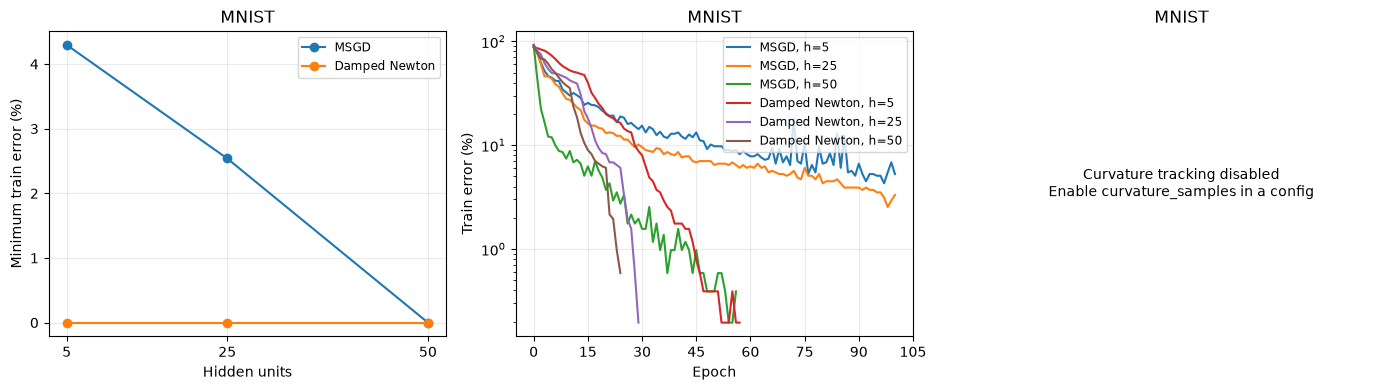

Saved: /Users/ken/Desktop/self-repositories/dauphin-sfn/results/figure3_msgd_newton


In [5]:
output_dir = ROOT / "results" / "figure3_msgd_newton"
output_dir.mkdir(parents=True, exist_ok=True)
dataset_names = list(dict.fromkeys(run["dataset"] for run in results))
plot_functions = (
    plot_training_error_by_hidden_units,
    plot_training_error_by_epoch,
    plot_negative_curvature_by_epoch,
)
figure, axes = plt.subplots(len(dataset_names), 3, figsize=(14, 4 * len(dataset_names)), squeeze=False)
for row, name in enumerate(dataset_names):
    dataset_results = [run for run in results if run["dataset"] == name]
    for column, plot in enumerate(plot_functions):
        plot(dataset_results, ax=axes[row, column])
figure.tight_layout()
figure.savefig(output_dir / "figure3.png", dpi=150, bbox_inches="tight")
record = {"torch_version": str(torch.__version__), "runs": results}
(output_dir / "runs.json").write_text(json.dumps(record, indent=2, allow_nan=False))
plt.show()
print("Saved:", output_dir)